In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import json

from Components.System import SimpleSquareExample
from Components.Model import IrrigationSchedulingModel, IrrigationSchedulingCostQuadraticDistance

In [6]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

np.printoptions(linewidth=np.inf)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Create model

In [9]:
parameter_file = "run_data/two_wells_analysis/finite_welfare/run_20251107-112119/two_wells_analysis_parameters_changed.json"
crop_repartition = np.array([[1., 1.], [0., 0.], [0., 0.], [0., 0.]])

In [22]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = IrrigationSchedulingModel(parameter_file, boundary_condition="Constant Head")

# Step command

In [23]:
heads = [system.get_heads_at_wells()]
for t in range(300):
    system.apply_command(-100*np.array([[1,1]]).T)
    heads.append(system.get_heads_at_wells())

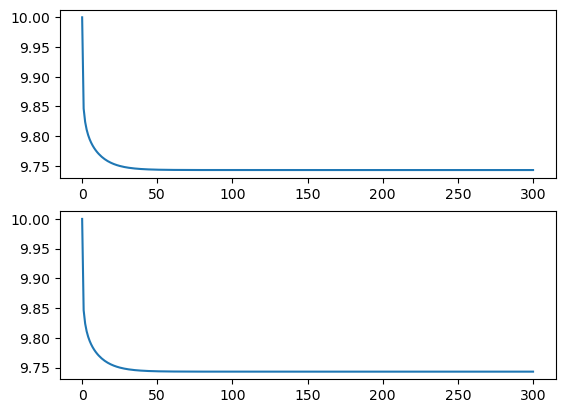

In [27]:
heads = np.array(heads)

fig, ax = plt.subplots(2,1)
ax[0].plot(heads[:,0])
ax[1].plot(heads[:,1])

plt.show()

In [59]:
x_tau = (heads[0,:] - heads[-1,:]) * (1 - 1/np.e)
x_tau

array([0.16243929, 0.1623591 ], dtype=float32)

In [76]:
tau = np.array([np.searchsorted(heads[0,0] - heads[:,0], x_tau[0]), np.searchsorted(heads[0,1] - heads[:,1], x_tau[1])])-1

In [77]:
tau

array([1, 1])

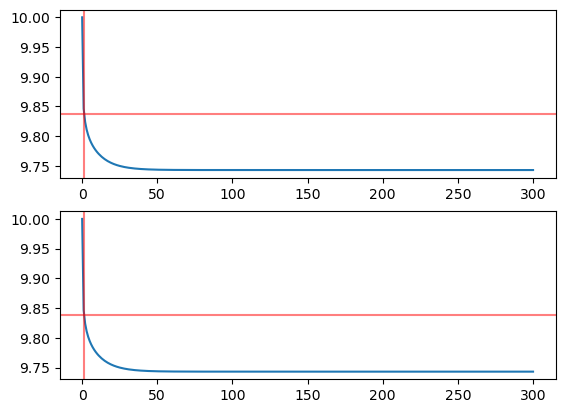

In [78]:
heads = np.array(heads)

fig, ax = plt.subplots(2,1)
ax[0].plot(heads[:,0])
ax[1].plot(heads[:,1])

ax[0].axhline(heads[0,0] - x_tau[0], color='r', alpha=0.5)
ax[0].axvline(tau[0], color='r', alpha=0.5)

ax[1].axhline(heads[0,1] - x_tau[1], color='r', alpha=0.5)
ax[1].axvline(tau[1], color='r', alpha=0.5)

plt.show()